In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer #datasetik
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler

In [2]:
#нормальное обучение
random_st = 42
data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=random_st)

rf = RandomForestClassifier(n_estimators=300, random_state=random_st, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

acc_raw = accuracy_score(y_test, y_pred)
print(f"Некий аccuracy: {acc_raw:.4f}")

Некий аccuracy: 0.9580


In [3]:
#бахнули рса 95
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

pca = PCA(n_components=0.95, random_state=random_st)
X_train_pca = pca.fit_transform(X_train_sc)
X_test_pca  = pca.transform(X_test_sc)

print(f"95% некой дисперсии: {pca.n_components_}")

95% некой дисперсии: 10


In [4]:
#обучение на сжатых признаках
rf_pca = RandomForestClassifier(n_estimators=300, random_state=random_st, n_jobs=-1)
rf_pca.fit(X_train_pca, y_train)
y_pred_pca = rf_pca.predict(X_test_pca)

acc_pca = accuracy_score(y_test, y_pred_pca)
print(f"Некий аccuracy после PCA: {acc_pca:.4f}")
print(f"Шок разница: {acc_pca - acc_raw:+.4f} ({(acc_pca-acc_raw)/acc_raw*100:+.2f}%)")

Некий аccuracy после PCA: 0.9510
Шок разница: -0.0070 (-0.73%)


> Обучите ту же модель на сжатых признаках. Упало ли качество? Насколько сильно?

Ну, качество упало, но не слишком сильно, с 0.9580 до 0.9510


In [5]:
!pip install umap-learn
import umap
import matplotlib.pyplot as plt

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


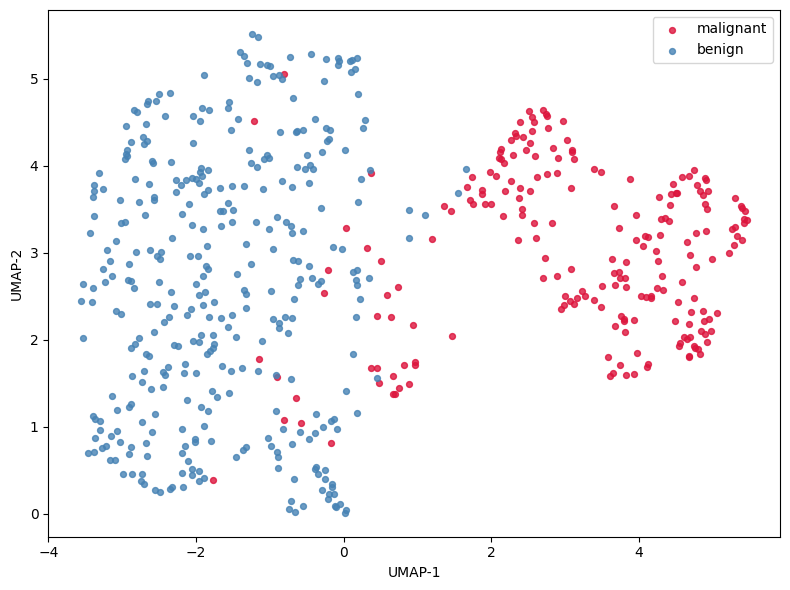

In [7]:
X_scaled = StandardScaler().fit_transform(X)

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1,
                    n_components=2, random_state=random_st)
embedding = reducer.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
for cls, name, color in [(0, "malignant", "crimson"), (1, "benign", "steelblue")]:
    mask = y == cls
    plt.scatter(embedding[mask, 0], embedding[mask, 1],
                s=18, alpha=0.8, c=color, label=name)
plt.xlabel("UMAP-1"); plt.ylabel("UMAP-2")
plt.legend(); plt.tight_layout()
plt.show()